In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

from sklearn.feature_selection import RFE, SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('../data/processed/preprocessed_data.csv')

print("Preprocessed data loaded")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Preprocessed data loaded
Shape: (938599, 15)
Columns: ['diameter', 'om', 'w', 'ma', 'a_log', 'q_log', 'n_log', 'i_log', 'moid_log', 'e_log', 'H_log', 'diameter_log', 'neo_encoded', 'pha_encoded', 'class_encoded']


In [3]:

# Case 1: PHA Classification
# Target: pha_encoded
# Drop leakage: moid_log, H_log, class_encoded, neo_encoded, 
#               diameter, diameter_log

drop_for_case1 = ['moid_log', 'H_log', 'class_encoded', 
                   'neo_encoded', 'diameter', 'diameter_log', 
                   'pha_encoded']

X = df.drop(columns=drop_for_case1, errors='ignore')
y = df['pha_encoded']

print("Features:", X.shape[1])
print("Feature names:", X.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts())

Features: 8
Feature names: ['om', 'w', 'ma', 'a_log', 'q_log', 'n_log', 'i_log', 'e_log']

Target distribution:
pha_encoded
0    936533
1      2066
Name: count, dtype: int64


In [4]:
#Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (750879, 8)
Test: (187720, 8)


In [9]:
# Feature Selection using RFE
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)

rfe = RFE(estimator=rf, n_features_to_select=4)
rfe.fit(X_train, y_train)

rfe_features = X_train.columns[rfe.support_].tolist()

print("RFE selected:", rfe_features)

RFE selected: ['w', 'ma', 'q_log', 'e_log']


In [10]:
#Feature Selection — Tree Importance
# Feature importance from Random Forest
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

print("Tree importance:")
print(importances)

tree_features = importances.head(4).index.tolist()
print("\nTree top 4:", tree_features)

Tree importance:
q_log    0.173655
e_log    0.148495
ma       0.127191
w        0.117987
i_log    0.115165
n_log    0.111682
a_log    0.110084
om       0.095741
dtype: float64

Tree top 4: ['q_log', 'e_log', 'ma', 'w']


In [11]:
# Feature Selection — Statistical Test
# Statistical test - ANOVA F-test
selector = SelectKBest(f_classif, k=4)
selector.fit(X_train, y_train)

stats_features = X_train.columns[selector.get_support()].tolist()

print("Statistical test:", stats_features)

Statistical test: ['a_log', 'q_log', 'n_log', 'e_log']


In [12]:

print("FEATURE SELECTION COMPARISON")

print("RFE:", rfe_features)
print("Tree:", tree_features)
print("Stats:", stats_features)

common = set(rfe_features) & set(tree_features) & set(stats_features)
print("\nCommon:", list(common))

FEATURE SELECTION COMPARISON
RFE: ['w', 'ma', 'q_log', 'e_log']
Tree: ['q_log', 'e_log', 'ma', 'w']
Stats: ['a_log', 'q_log', 'n_log', 'e_log']

Common: ['q_log', 'e_log']


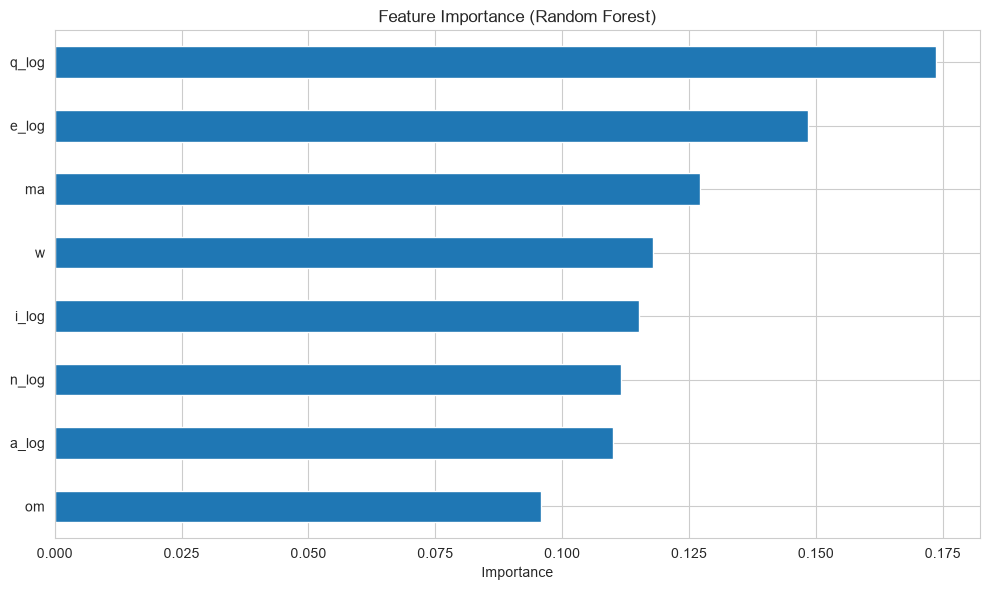

In [13]:
plt.figure(figsize=(10, 6))
importances.plot(kind='barh')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [14]:
final_features = list(set(rfe_features) | set(tree_features) | set(stats_features))

print("Final selected features:", final_features)
print("Total:", len(final_features))

Final selected features: ['n_log', 'w', 'ma', 'e_log', 'a_log', 'q_log']
Total: 6


In [15]:
with open('../data/processed/selected_features.json', 'w') as f:
    json.dump(final_features, f)

print("Features saved")
print(final_features)

Features saved
['n_log', 'w', 'ma', 'e_log', 'a_log', 'q_log']
